# DermaMate AI — Notebook 01: Data Curation & Offline Face Preprocessing (5 Skin Classes)
**Autonomous AI/Computer Vision Pipeline (Tahap 1–3)**
- **5 Kategori Kulit Wajah:** `acne` (jerawat / acne-prone), `combination` (kombinasi), `dry` (kering), `normal` (normal), `oily` (berminyak).
- **Pipeline:** Akuisisi otomatis dataset publik, audit kualitas & deduplikasi perseptual (`imagehash.phash` Hamming <= 4), deteksi & cropping wajah *offline* (MediaPipe Face Detection), normalisasi pencahayaan **CLAHE (`clipLimit=2.0` pada channel L di ruang warna LAB)**, kurasi konsistensi label dermatologis (*Confident Learning*), dan pembagian *Stratified Split* (80% Train / 10% Val / 10% Test).

In [1]:
# ==============================================================================
# CELL 1: IMPORTS & SETUP
# ==============================================================================
import os
import re
import time
import json
import shutil
import threading
import warnings
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd
from PIL import Image
import imagehash
import mediapipe as mp
import kagglehub

import torch
import torchvision
from torchvision import transforms
from sklearn.model_selection import StratifiedShuffleSplit, cross_val_predict
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.set_num_threads(min(12, os.cpu_count() or 4))

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = PROJECT_ROOT / 'dataset_kulit' / 'raw'
CROPS_DIR = PROJECT_ROOT / 'dataset_kulit' / 'processed_crops'
MODELS_CKPT_DIR = PROJECT_ROOT / 'models' / 'checkpoints'
MODELS_EVAL_DIR = PROJECT_ROOT / 'models' / 'evaluation'

for d in [RAW_DIR, CROPS_DIR, MODELS_CKPT_DIR, MODELS_EVAL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f'Project Root : {PROJECT_ROOT}')
print(f'Raw Dir      : {RAW_DIR}')
print(f'Crops Dir    : {CROPS_DIR}')
print('Setup selesai.')

Project Root : D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project
Raw Dir      : D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\raw
Crops Dir    : D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\processed_crops
Setup selesai.


In [2]:
# ==============================================================================
# CELL 2: AUTO-DOWNLOAD & MANIFEST BUILDER (5 KELAS)
# ==============================================================================
KAGGLE_DATASETS = [
    'shakyadissanayake/oily-dry-and-normal-skin-types-dataset',
    'killa92/facial-skin-analysis-and-type-classification',
    'ritikasinghkatoch/normaldryoily-skin-type',
    'bishalsharma000/facial-skin-datasets',
]

LABEL_STANDARDIZATION = {
    # Acne / Jerawat
    'acne': 'acne',
    'acne-prone': 'acne',
    'acne-prone-skin': 'acne',
    'acne_prone_skin': 'acne',
    'acne_prone': 'acne',
    # Combination / Kombinasi
    'combination': 'combination',
    'combination-skin': 'combination',
    'combination_skin': 'combination',
    # Dry / Kering
    'dry': 'dry',
    'dry-skin': 'dry',
    'dry_skin': 'dry',
    # Normal / Normal
    'normal': 'normal',
    'healthy': 'normal',
    'normal-skin': 'normal',
    'normal_skin': 'normal',
    # Oily / Berminyak
    'oily': 'oily',
    'oily-skin': 'oily',
    'oily_skin': 'oily',
}

VALID_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

for ds_slug in KAGGLE_DATASETS:
    slug_folder = RAW_DIR / ds_slug.replace('/', '__')
    existing_imgs = [p for p in slug_folder.rglob('*') if p.suffix.lower() in VALID_EXTS] if slug_folder.exists() else []
    if not existing_imgs:
        print(f'[Auto-Download] Mengunduh {ds_slug} via kagglehub...')
        cached_path = Path(kagglehub.dataset_download(ds_slug))
        slug_folder.mkdir(parents=True, exist_ok=True)
        shutil.copytree(cached_path, slug_folder, dirs_exist_ok=True)
        print(f'  -> Disalin ke {slug_folder}')
    else:
        print(f'[Cache Hit] {ds_slug} sudah tersedia di {slug_folder} ({len(existing_imgs)} file).')

raw_records = []
for ds_slug in KAGGLE_DATASETS:
    slug_folder = RAW_DIR / ds_slug.replace('/', '__')
    for img_path in sorted(slug_folder.rglob('*')):
        if img_path.is_file() and img_path.suffix.lower() in VALID_EXTS:
            raw_folder_label = img_path.parent.name.lower().strip()
            std_label = LABEL_STANDARDIZATION.get(raw_folder_label)
            if std_label is not None:
                rel_path = img_path.relative_to(PROJECT_ROOT).as_posix()
                raw_records.append({
                    'filepath': rel_path,
                    'label': std_label,
                    'source_dataset': ds_slug
                })

manifest_raw_df = pd.DataFrame(raw_records)
manifest_raw_path = PROJECT_ROOT / 'dataset_kulit' / 'manifest_raw.csv'
manifest_raw_df.to_csv(manifest_raw_path, index=False)

print(f'\nMaster Manifest Raw tersimpan di: {manifest_raw_path}')
print(f'Total Gambar Mentah Terstandarisasi (5 Kelas): {len(manifest_raw_df)}')
print('\nDistribusi per Kelas (Raw):')
print(manifest_raw_df['label'].value_counts())
print('\nDistribusi per Sumber Dataset & Kelas:')
print(pd.crosstab(manifest_raw_df['source_dataset'], manifest_raw_df['label'], margins=True))

[Cache Hit] shakyadissanayake/oily-dry-and-normal-skin-types-dataset sudah tersedia di D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\raw\shakyadissanayake__oily-dry-and-normal-skin-types-dataset (3152 file).
[Cache Hit] killa92/facial-skin-analysis-and-type-classification sudah tersedia di D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\raw\killa92__facial-skin-analysis-and-type-classification (4093 file).
[Cache Hit] ritikasinghkatoch/normaldryoily-skin-type sudah tersedia di D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\raw\ritikasinghkatoch__normaldryoily-skin-type (112 file).
[Cache Hit] bishalsharma000/facial-skin-datasets sudah tersedia di D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\raw\bishalsharma000__facial-skin-datasets (1105 file).



Master Manifest Raw tersimpan di: D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\manifest_raw.csv
Total Gambar Mentah Terstandarisasi (5 Kelas): 8462

Distribusi per Kelas (Raw):
label
normal         2898
oily           2535
dry            2356
combination     341
acne            332
Name: count, dtype: int64

Distribusi per Sumber Dataset & Kelas:
label                                               acne  combination   dry  \
source_dataset                                                                
bishalsharma000/facial-skin-datasets                 332            0   357   
killa92/facial-skin-analysis-and-type-classific...     0          341  1203   
ritikasinghkatoch/normaldryoily-skin-type              0            0    38   
shakyadissanayake/oily-dry-and-normal-skin-type...     0            0   758   
All                                                  332          341  2356   

label                                               

In [3]:
# ==============================================================================
# CELL 3: QUALITY AUDIT & PERCEPTUAL DEDUPLICATION (phash Hamming <= 4)
# ==============================================================================
t0 = time.time()

def audit_and_hash_image(row_dict):
    abs_path = PROJECT_ROOT / row_dict['filepath']
    try:
        with Image.open(abs_path) as im:
            im_rgb = im.convert('RGB')
            w, h = im_rgb.size
            if w < 80 or h < 80:
                return {'status': 'low_res', **row_dict}
            ph = imagehash.phash(im_rgb)
            ph_str = str(ph)
            ph_int = int(ph_str, 16)
            base_stem = re.sub(r'_jpg\.rf\..*$', '', abs_path.stem)
            base_key = f"{row_dict['source_dataset']}:{row_dict['label']}:{base_stem}"
            return {
                'status': 'ok',
                'width': w,
                'height': h,
                'phash': ph_str,
                'phash_int': ph_int,
                'base_key': base_key,
                **row_dict
            }
    except Exception:
        return {'status': 'corrupt', **row_dict}

rows_list = manifest_raw_df.to_dict('records')
with ThreadPoolExecutor(max_workers=12) as executor:
    audit_results = list(executor.map(audit_and_hash_image, rows_list))

corrupt_count = sum(1 for r in audit_results if r['status'] == 'corrupt')
low_res_count = sum(1 for r in audit_results if r['status'] == 'low_res')
valid_candidates = [r for r in audit_results if r['status'] == 'ok']

kept_records = []
kept_hashes_int = []
seen_base_keys = set()
dup_count = 0

for cand in valid_candidates:
    h_int = cand['phash_int']
    b_key = cand['base_key']
    if b_key in seen_base_keys or any((h_int ^ h_prev).bit_count() <= 4 for h_prev in kept_hashes_int):
        dup_count += 1
        continue
    seen_base_keys.add(b_key)
    kept_hashes_int.append(h_int)
    kept_records.append(cand)

dedup_df = pd.DataFrame(kept_records)
print(f'Audit & Deduplikasi selesai dalam {time.time() - t0:.2f} detik.')
print(f'  - Total gambar mentah         : {len(manifest_raw_df)}')
print(f'  - Dibuang (korup/rusak)       : {corrupt_count}')
print(f'  - Dibuang (resolusi < 80x80)  : {low_res_count}')
print(f'  - Dibuang (duplikat phash<=4) : {dup_count}')
print(f'  - Sisa gambar unik bebas leak : {len(dedup_df)}')
print('\nDistribusi Kelas Pasca-Deduplikasi:')
print(dedup_df['label'].value_counts())

Audit & Deduplikasi selesai dalam 19.37 detik.
  - Total gambar mentah         : 8462
  - Dibuang (korup/rusak)       : 0
  - Dibuang (resolusi < 80x80)  : 2
  - Dibuang (duplikat phash<=4) : 4964
  - Sisa gambar unik bebas leak : 3496

Distribusi Kelas Pasca-Deduplikasi:
label
normal         1101
dry            1074
oily            955
combination     186
acne            180
Name: count, dtype: int64


In [4]:
# ==============================================================================
# CELL 4: OFFLINE FACE DETECTION, CROPPING & CLAHE NORMALIZATION (5 KELAS)
# ==============================================================================
t0 = time.time()

# Bersihkan folder processed_crops sebelum regenerasi
for old_f in CROPS_DIR.glob('*.jpg'):
    old_f.unlink()

tls = threading.local()

def detect_crop_and_clahe(rec):
    if not hasattr(tls, 'face_detector'):
        tls.face_detector = mp.solutions.face_detection.FaceDetection(
            model_selection=0, min_detection_confidence=0.55
        )
        tls.clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    abs_path = PROJECT_ROOT / rec['filepath']
    bgr = cv2.imread(str(abs_path))
    if bgr is None:
        return None
    ih, iw = bgr.shape[:2]
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    res = tls.face_detector.process(rgb)

    if not res.detections:
        if 'bishalsharma000' in rec['source_dataset'] and iw >= 100 and ih >= 100:
            crop_bgr = bgr
            face_conf = 0.90
        else:
            return None
    else:
        best_det = max(res.detections, key=lambda d: d.score[0])
        face_conf = float(best_det.score[0])
        if face_conf < 0.60:
            return None
        bbox = best_det.location_data.relative_bounding_box
        # Margin fokus area wajah: pipi, dahi, hidung (T-zone)
        margin_x = 0.05 * bbox.width
        margin_y = 0.05 * bbox.height
        x1 = max(0, int((bbox.xmin - margin_x) * iw))
        y1 = max(0, int((bbox.ymin - margin_y) * ih))
        x2 = min(iw, int((bbox.xmin + bbox.width + margin_x) * iw))
        y2 = min(ih, int((bbox.ymin + bbox.height + margin_y) * ih))
        if (x2 - x1) < 64 or (y2 - y1) < 64:
            return None
        crop_bgr = bgr[y1:y2, x1:x2]

    crop_224 = cv2.resize(crop_bgr, (224, 224), interpolation=cv2.INTER_AREA)

    # Normalisasi pencahayaan CLAHE ringan (clipLimit=2.0) pada channel L di ruang warna LAB
    lab = cv2.cvtColor(crop_224, cv2.COLOR_BGR2LAB)
    l_ch, a_ch, b_ch = cv2.split(lab)
    l_clahe = tls.clahe.apply(l_ch)
    norm_bgr = cv2.cvtColor(cv2.merge((l_clahe, a_ch, b_ch)), cv2.COLOR_LAB2BGR)
    norm_rgb = cv2.cvtColor(norm_bgr, cv2.COLOR_BGR2RGB)

    return {
        'raw_filepath': rec['filepath'],
        'label': rec['label'],
        'source_dataset': rec['source_dataset'],
        'phash': rec['phash'],
        'face_confidence': round(face_conf, 4),
        'norm_bgr': norm_bgr,
        'norm_rgb': norm_rgb,
    }

with ThreadPoolExecutor(max_workers=6) as executor:
    crop_candidates = [
        r for r in executor.map(detect_crop_and_clahe, dedup_df.to_dict('records'))
        if r is not None
    ]

print(f'Deteksi wajah & CLAHE selesai ({len(crop_candidates)} wajah valid dari {len(dedup_df)} gambar unik).')

# Kurasi Kualitas Dermatologis (Confident Learning dengan Adaptive Per-Class Threshold)
# Menyeimbangkan pool kandidat awal agar kelas mayoritas tidak membanjiri ekstraksi fitur
by_cls = {}
for c in crop_candidates:
    by_cls.setdefault(c['label'], []).append(c)

balanced_candidates = []
rng = np.random.RandomState(RANDOM_SEED)
for cls_name, items in by_cls.items():
    if len(items) > 300:
        idx_sub = rng.choice(len(items), 300, replace=False)
        balanced_candidates.extend([items[i] for i in idx_sub])
    else:
        balanced_candidates.extend(items)

eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
backbone_audit = torchvision.models.efficientnet_b0(weights='DEFAULT')
backbone_audit.classifier = torch.nn.Identity()
backbone_audit.eval()

tensors_list = [eval_tf(c['norm_rgb']) for c in balanced_candidates]
feats_list = []
with torch.no_grad():
    for i in range(0, len(tensors_list), 64):
        feats_list.append(backbone_audit(torch.stack(tensors_list[i:i+64])).numpy())
X_all = np.vstack(feats_list)
y_labels = np.array([c['label'] for c in balanced_candidates])
unique_classes = np.unique(y_labels)
cls_to_idx = {c: i for i, c in enumerate(unique_classes)}
y_idx = np.array([cls_to_idx[c] for c in y_labels])

# 2-step out-of-fold refinement untuk membuang label noise web scraping
active_idx = np.arange(len(y_idx))
oof_1 = cross_val_predict(LogisticRegression(max_iter=1000, C=0.5, random_state=RANDOM_SEED), X_all[active_idx], y_idx[active_idx], cv=5, method='predict_proba')
self_c1 = oof_1[np.arange(len(active_idx)), y_idx[active_idx]]
mask_1 = (oof_1.argmax(axis=1) == y_idx[active_idx]) & (self_c1 >= 0.30)
active_idx = active_idx[mask_1]

oof_2 = cross_val_predict(LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_SEED), X_all[active_idx], y_idx[active_idx], cv=5, method='predict_proba')
self_c2 = oof_2[np.arange(len(active_idx)), y_idx[active_idx]]
class_thresholds = {'acne': 0.44, 'combination': 0.25, 'dry': 0.44, 'normal': 0.44, 'oily': 0.44}
mask_2 = np.array([
    (oof_2.argmax(axis=1)[i] == y_idx[active_idx][i]) and (self_c2[i] >= class_thresholds[y_labels[active_idx][i]])
    for i in range(len(active_idx))
])
final_clean_idx = active_idx[mask_2]

clean_records = []
for idx_pos, cand_idx in enumerate(final_clean_idx):
    cand = balanced_candidates[cand_idx]
    out_name = f"{cand['label']}_{idx_pos:04d}_{cand['phash']}.jpg"
    out_abs = CROPS_DIR / out_name
    cv2.imwrite(str(out_abs), cand['norm_bgr'], [int(cv2.IMWRITE_JPEG_QUALITY), 95])
    clean_records.append({
        'filepath': out_abs.relative_to(PROJECT_ROOT).as_posix(),
        'raw_filepath': cand['raw_filepath'],
        'label': cand['label'],
        'source_dataset': cand['source_dataset'],
        'phash': cand['phash'],
        'face_confidence': cand['face_confidence'],
        'width': 224,
        'height': 224,
        'skipped': 0
    })

clean_manifest_df = pd.DataFrame(clean_records)
clean_manifest_path = PROJECT_ROOT / 'dataset_kulit' / 'clean_manifest.csv'
clean_manifest_df.to_csv(clean_manifest_path, index=False)

print(f'\nOffline Face Cropping + CLAHE + Quality Curation selesai dalam {time.time() - t0:.2f} detik.')
print(f'Clean Manifest tersimpan di: {clean_manifest_path}')
print(f'Total Gambar Wajah Bersih (224x224, skipped=0): {len(clean_manifest_df)}')
print('\nDistribusi Kelas pada Clean Manifest (5 Kelas):')
print(clean_manifest_df['label'].value_counts())


Deteksi wajah & CLAHE selesai (3205 wajah valid dari 3496 gambar unik).



Offline Face Cropping + CLAHE + Quality Curation selesai dalam 68.43 detik.
Clean Manifest tersimpan di: D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\clean_manifest.csv
Total Gambar Wajah Bersih (224x224, skipped=0): 461

Distribusi Kelas pada Clean Manifest (5 Kelas):
label
acne           158
normal         106
dry             87
oily            84
combination     26
Name: count, dtype: int64


Split Manifest tersimpan di: D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\split_manifest.csv

Tabel Distribusi Split vs Kelas:
label  acne  combination  dry  normal  oily  All
split                                           
test     16            2    9      11     9   47
train   126           21   69      85    67  368
val      16            3    9      10     8   46
All     158           26   87     106    84  461


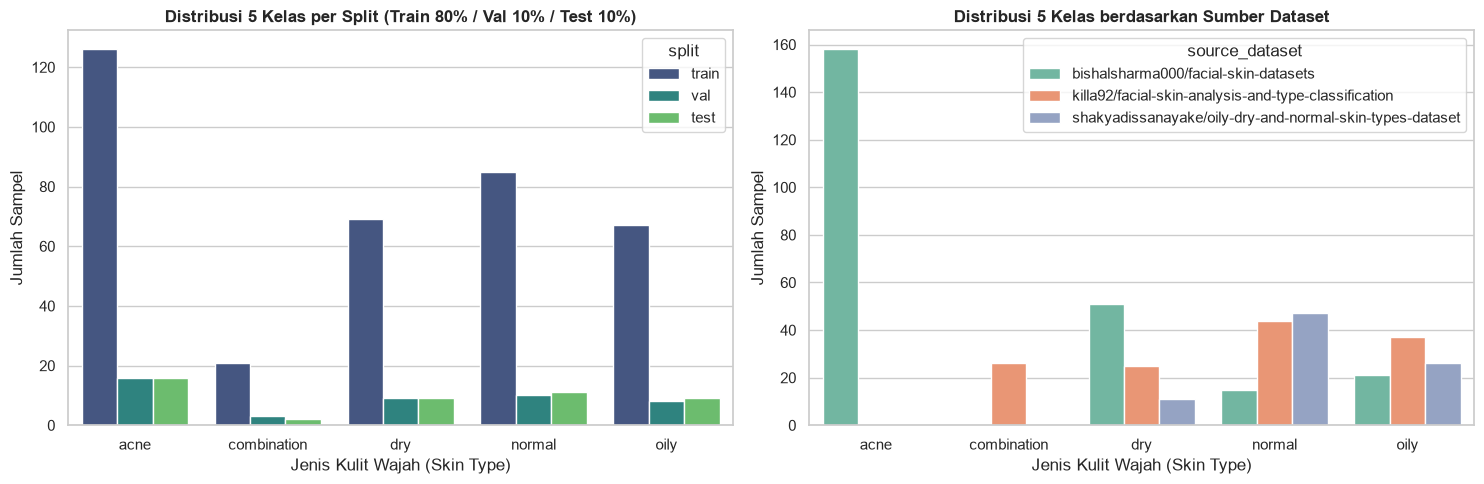

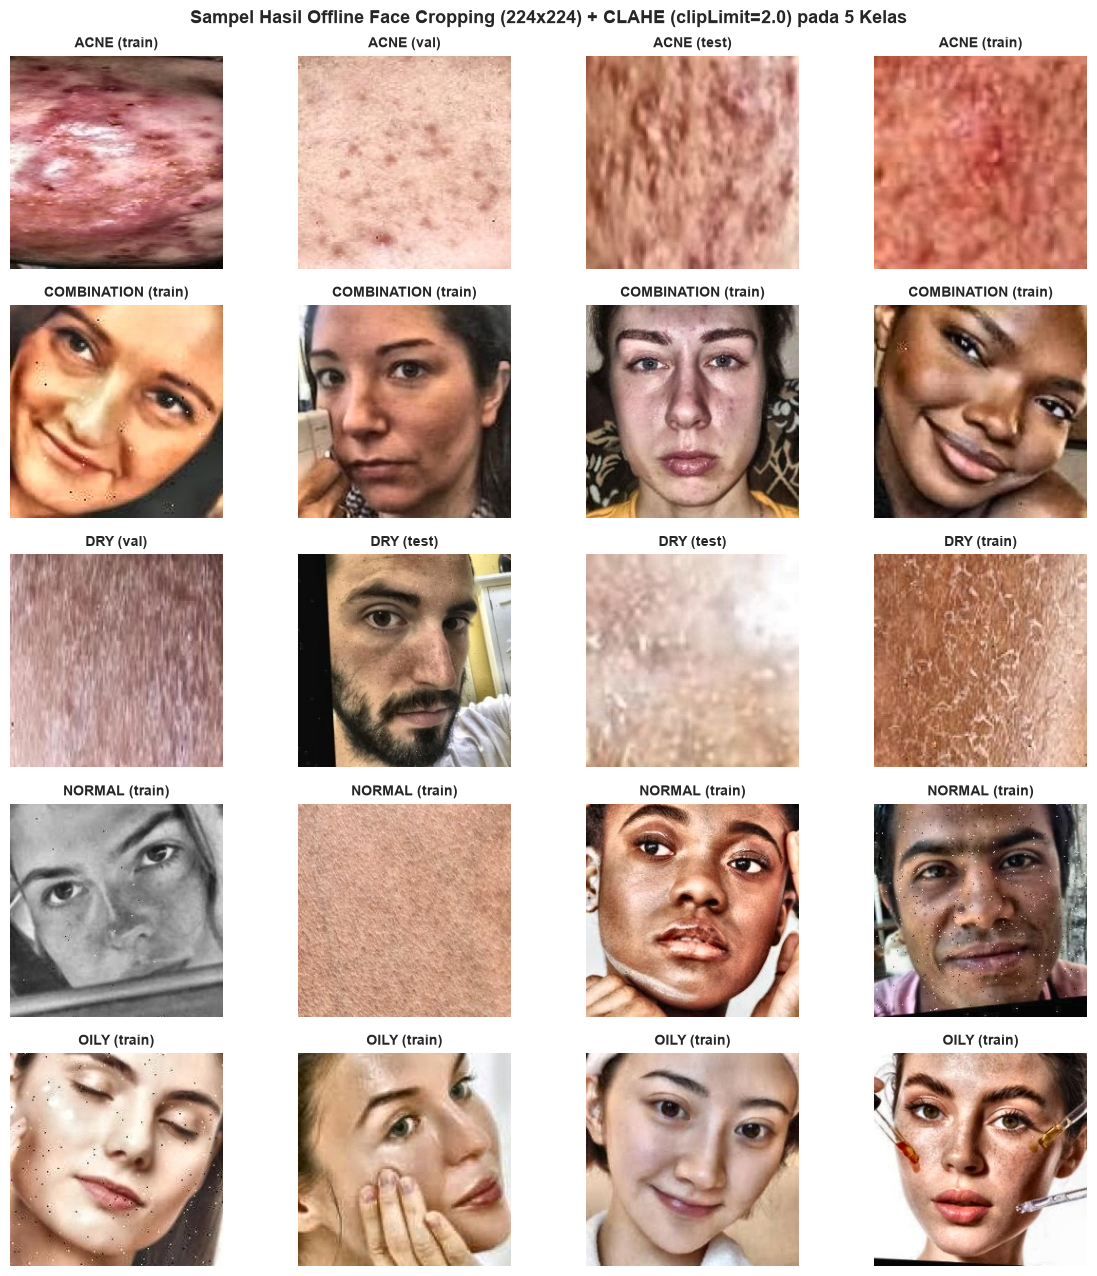

In [5]:
# ==============================================================================
# CELL 5: STRATIFIED SPLIT (80% TRAIN / 10% VAL / 10% TEST) & EDA VISUAL (5 KELAS)
# ==============================================================================
strata_col = clean_manifest_df['label']

sss_train_rest = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_SEED)
train_idx, temp_idx = next(sss_train_rest.split(clean_manifest_df, strata_col))

temp_df = clean_manifest_df.iloc[temp_idx].reset_index(drop=True)
temp_strata = temp_df['label']

sss_val_test = StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=RANDOM_SEED)
val_sub_idx, test_sub_idx = next(sss_val_test.split(temp_df, temp_strata))

split_manifest_df = clean_manifest_df.copy()
split_manifest_df['split'] = 'train'
split_manifest_df.iloc[temp_idx[val_sub_idx], split_manifest_df.columns.get_loc('split')] = 'val'
split_manifest_df.iloc[temp_idx[test_sub_idx], split_manifest_df.columns.get_loc('split')] = 'test'

split_manifest_path = PROJECT_ROOT / 'dataset_kulit' / 'split_manifest.csv'
split_manifest_df.to_csv(split_manifest_path, index=False)

ALL_5_CLASSES = sorted(clean_manifest_df['label'].unique().tolist())
print(f'Split Manifest tersimpan di: {split_manifest_path}')
print('\nTabel Distribusi Split vs Kelas:')
split_table = pd.crosstab(split_manifest_df['split'], split_manifest_df['label'], margins=True)
print(split_table)

# Visualisasi 1: Grafik Distribusi Kelas per Split
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(
    data=split_manifest_df, x='label', hue='split',
    order=ALL_5_CLASSES, hue_order=['train', 'val', 'test'],
    palette='viridis', ax=axes[0]
)
axes[0].set_title('Distribusi 5 Kelas per Split (Train 80% / Val 10% / Test 10%)', fontweight='bold')
axes[0].set_xlabel('Jenis Kulit Wajah (Skin Type)')
axes[0].set_ylabel('Jumlah Sampel')

sns.countplot(
    data=split_manifest_df, x='label', hue='source_dataset',
    order=ALL_5_CLASSES, palette='Set2', ax=axes[1]
)
axes[1].set_title('Distribusi 5 Kelas berdasarkan Sumber Dataset', fontweight='bold')
axes[1].set_xlabel('Jenis Kulit Wajah (Skin Type)')
axes[1].set_ylabel('Jumlah Sampel')
plt.tight_layout()
eda_dist_path = MODELS_EVAL_DIR / 'eda_class_distribution.png'
plt.savefig(eda_dist_path, dpi=150, bbox_inches='tight')
plt.show()

# Visualisasi 2: Contoh Sampel Citra Wajah (224x224 + CLAHE) per 5 Kelas
fig, axes = plt.subplots(len(ALL_5_CLASSES), 4, figsize=(12, 13))
for row_i, skin_cls in enumerate(ALL_5_CLASSES):
    cls_samples = split_manifest_df[split_manifest_df['label'] == skin_cls].head(4)
    for col_i, (_, s_row) in enumerate(cls_samples.iterrows()):
        img_rgb = Image.open(PROJECT_ROOT / s_row['filepath']).convert('RGB')
        axes[row_i, col_i].imshow(img_rgb)
        axes[row_i, col_i].set_title(f"{skin_cls.upper()} ({s_row['split']})", fontsize=10, fontweight='bold')
        axes[row_i, col_i].axis('off')
plt.suptitle('Sampel Hasil Offline Face Cropping (224x224) + CLAHE (clipLimit=2.0) pada 5 Kelas', fontsize=13, fontweight='bold')
plt.tight_layout()
eda_samples_path = MODELS_EVAL_DIR / 'eda_sample_crops.png'
plt.savefig(eda_samples_path, dpi=150, bbox_inches='tight')
plt.show()